# Financial vs. Topological Market Regimes Using K-Means on the IHSG

This notebook compares two representations of the Indonesian Composite Stock Price Index (IHSG):

$$
\boxed{\text{Financial features}\ \rightarrow\ \text{K-Means }(k=2)}
\qquad\text{vs.}\qquad
\boxed{\text{TDA features}\ \rightarrow\ \text{K-Means }(k=2)}
$$

The analysis uses **IHSG data only**. Financial features are derived from the index's OHLCV series. Topological features are derived from a time-delay embedding of IHSG daily log returns, followed by Vietoris-Rips persistent homology for $(H_0)$ and $(H_1)$. No individual-stock prices, stock correlations, or cross-sectional stock statistics are used.

The main research comparison uses two regimes for each feature representation. The notebook also evaluates candidate cluster counts $(k\in\{2,\ldots,8\})$ on the calibration period and retains Financial+TDA clustering with $(k=3)$ as a secondary exploratory analysis.

The notebook evaluates cluster separation, cluster stability, regime profiles, agreement between Financial and TDA regimes, transition probabilities, and regime transitions before reference drawdown events. Reference events are used for evaluation only and are not clustering inputs.

## 1. Methodological overview

The topological pipeline follows a univariate time-series approach:

$$
\text{IHSG log returns}
\rightarrow
\text{time-delay embedding}
\rightarrow
\text{Vietoris-Rips filtration}
\rightarrow
\text{persistent homology }(H_0,H_1)
\rightarrow
\text{TDA features}
\rightarrow
\text{K-Means}.
$$

For an endpoint $(t)$, a rolling return window is embedded into $(\mathbb{R}^m)$ using a fixed embedding dimension and delay. The resulting point cloud represents the local temporal structure of the single IHSG return series. Persistent homology summarizes connected components and loops over a range of distance scales.

The financial representation is computed independently from the same IHSG history. Features include cumulative return, realized and downside volatility, drawdown, intraday range, intraday return, overnight gap, and volume measures.

### Research question

Does the regime sequence identified from the topology of IHSG returns provide temporal information that differs from the sequence identified by conventional index-level financial features, particularly before large drawdown events?

### Calibration and test chronology

The scaler and K-Means centroids are fitted using data on or before `CALIBRATION_END`. The test observations are assigned to these fixed centroids. Test data are not used to refit the scaler or the K-Means model.

## 2. Environment and dependencies

The `ripser` package computes Vietoris-Rips persistent homology. If a dependency is missing in your notebook environment, uncomment and run the installation command below once.

In [3]:
%pip install -q ripser

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 842.1/842.1 kB 7.8 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.6/48.6 kB 1.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# %pip install -q yfinance scikit-learn seaborn openpyxl

In [25]:
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter
import numpy as np
import pandas as pd
import seaborn as sns
import yfinance as yf
from IPython.display import display
from ripser import ripser
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    cohen_kappa_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

sns.set_theme(style="darkgrid")
pd.set_option("display.max_columns", 200)

SEED = 42
np.random.seed(SEED)

# Yahoo Finance ticker for the Indonesian Composite Stock Price Index.
IHSG_TICKER = "^JKSE"
DOWNLOAD_START = "2005-12-01"
ANALYSIS_START = "2006-12-29"
END_DATE = "2026-09-01"  # Yahoo Finance uses an exclusive end date.
CALIBRATION_END = "2017-12-29"

# Each endpoint summarizes the previous W daily observations.
WINDOWS = [20, 40, 60]
STRIDE = 5
EMBEDDING_DIMENSION = 3
EMBEDDING_DELAY = 1

K_VALUES = range(2, 9)
KMEANS_N_INIT = 50
STABILITY_SEEDS = [11, 23, 37, 51, 71]
SCALER_KIND = "robust"  # Options: "standard", "robust", "minmax".

# Reference drawdown events are evaluation targets, not clustering features.
CRISIS_VOL_WINDOW = 20
CRISIS_VOL_HORIZON = 20
CRISIS_VOL_DRAWDOWN_KAPPA = 2.0
CRISIS_MIN_ABS_DRAWDOWN = 0.10
CRISIS_RECOVERY_LEVEL = 0.05
PRECRITICAL_LOOKBACK = 20
LEADTIME_LOOKBACKS = [20, 40, 60]
PRIMARY_LEADTIME_LOOKBACK = 20

PRIMARY_FEATURE_SETS = ["Financial", "TDA"]
PRIMARY_K = 2
EXPLORATORY_COMBINED_K = 3
ANALYSIS_K = {
    "Financial": PRIMARY_K,
    "TDA": PRIMARY_K,
    "Financial+TDA": EXPLORATORY_COMBINED_K,
}

OUTPUT_DIR = Path("data_ihsg_tda_kmeans")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 3. Download daily IHSG OHLCV data

The notebook downloads a single Yahoo Finance series, `^JKSE`. `Adjusted Close` is used to calculate log returns and drawdowns. The Open, High, Low, Close, and Volume columns are retained for additional index-level financial features.

In [6]:
ihsg_raw = yf.download(
    IHSG_TICKER,
    start=DOWNLOAD_START,
    end=END_DATE,
    interval="1d",
    auto_adjust=False,
    progress=False,
)

if ihsg_raw.empty:
    raise RuntimeError(
        f"No data were downloaded for {IHSG_TICKER}. "
        "Check the ticker, date range, internet connection, and Yahoo Finance availability."
    )

# Recent yfinance versions can return a MultiIndex even for a single ticker.
if isinstance(ihsg_raw.columns, pd.MultiIndex):
    ihsg_raw.columns = ihsg_raw.columns.get_level_values(0)

ihsg_raw = ihsg_raw.loc[:, ~ihsg_raw.columns.duplicated()].copy()
if "Adj Close" not in ihsg_raw.columns and "Close" in ihsg_raw.columns:
    ihsg_raw["Adj Close"] = ihsg_raw["Close"]

required_columns = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
missing_columns = [column for column in required_columns if column not in ihsg_raw.columns]
if missing_columns:
    raise ValueError(f"The downloaded IHSG data are missing required columns: {missing_columns}")

ihsg_raw.index = pd.to_datetime(ihsg_raw.index)
if getattr(ihsg_raw.index, "tz", None) is not None:
    ihsg_raw.index = ihsg_raw.index.tz_localize(None)

ihsg_ohlcv = ihsg_raw[required_columns].apply(pd.to_numeric, errors="coerce")
ihsg_ohlcv = ihsg_ohlcv.dropna(subset=required_columns).sort_index()
ihsg_ohlcv = ihsg_ohlcv.loc[~ihsg_ohlcv.index.duplicated(keep="last")]

if ihsg_ohlcv.empty:
    raise RuntimeError("The downloaded IHSG data contain no complete OHLCV rows.")

ihsg_ohlcv.to_csv(OUTPUT_DIR / "ihsg_ohlcv_download.csv", index_label="Date")

print("Downloaded IHSG observations:", len(ihsg_ohlcv))
print("Available period:", ihsg_ohlcv.index.min().date(), "to", ihsg_ohlcv.index.max().date())
display(ihsg_ohlcv.head())

Downloaded IHSG observations: 5023
Available period: 2005-12-01 to 2026-08-31


Price,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2005-12-01,1095.421997,1102.443970,1087.161987,1096.370972,1096.328247,11365400
2005-12-02,1102.529053,1119.416992,1102.529053,1119.416992,1119.373413,8524100
2005-12-05,1121.109009,1123.170044,1113.573975,1120.578003,1120.534424,7199500
2005-12-06,1121.630981,1129.037964,1119.800049,1123.435059,1123.391235,10024800
2005-12-07,1130.954956,1155.421021,1130.954956,1151.364990,1151.320190,20396400


## 4. Prepare the analysis series

Daily log returns are calculated before applying `ANALYSIS_START`. This keeps the previous trading day's close available for calculating the first return in the analysis period. No interpolation is performed. Rows with missing required OHLCV values are excluded from the downloaded series.

In [8]:
all_log_returns = np.log(ihsg_ohlcv["Adj Close"]).diff()
log_returns = (
    all_log_returns.loc[ANALYSIS_START:]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .rename("log_return")
)

if log_returns.empty:
    raise RuntimeError("No IHSG log returns remain after applying the analysis date range.")

ihsg_analysis = ihsg_ohlcv.reindex(log_returns.index).copy()
ihsg_price = ihsg_analysis["Adj Close"].rename("IHSG_Adj_Close")

calibration_return_mask = log_returns.index <= pd.Timestamp(CALIBRATION_END)
if calibration_return_mask.sum() < 100:
    raise ValueError("The calibration period contains too few daily returns. Check CALIBRATION_END.")

# Standardization parameters for TDA are learned only from calibration returns.
tda_return_mean = float(log_returns.loc[calibration_return_mask].mean())
tda_return_std = float(log_returns.loc[calibration_return_mask].std(ddof=1))
if not np.isfinite(tda_return_std) or tda_return_std <= 0:
    raise ValueError("Calibration returns have an invalid standard deviation.")
tda_returns = ((log_returns - tda_return_mean) / tda_return_std).rename("standardized_log_return")

print("Analysis observations:", len(log_returns))
print("Analysis period:", log_returns.index.min().date(), "to", log_returns.index.max().date())
print("Calibration ends on:", pd.Timestamp(CALIBRATION_END).date())
print("Calibration return mean:", round(tda_return_mean, 8))
print("Calibration return standard deviation:", round(tda_return_std, 8))

display(pd.DataFrame({"IHSG_Adjusted_Close": ihsg_price, "Log_Return": log_returns}).head())

Analysis observations: 4761
Analysis period: 2007-01-02 to 2026-08-31
Calibration ends on: 2017-12-29
Calibration return mean: 0.00047048
Calibration return standard deviation: 0.01361331


,IHSG_Adjusted_Close,Log_Return
Date,,
2007-01-02,1836.448608,0.017022
2007-01-03,1834.637573,-0.000987
2007-01-04,1824.032104,-0.005797
2007-01-05,1832.478638,0.004620
2007-01-08,1813.323486,-0.010508


## 5. Explore IHSG prices and returns

The first plot shows the index level and daily log returns. These plots are descriptive only and do not determine the clusters.

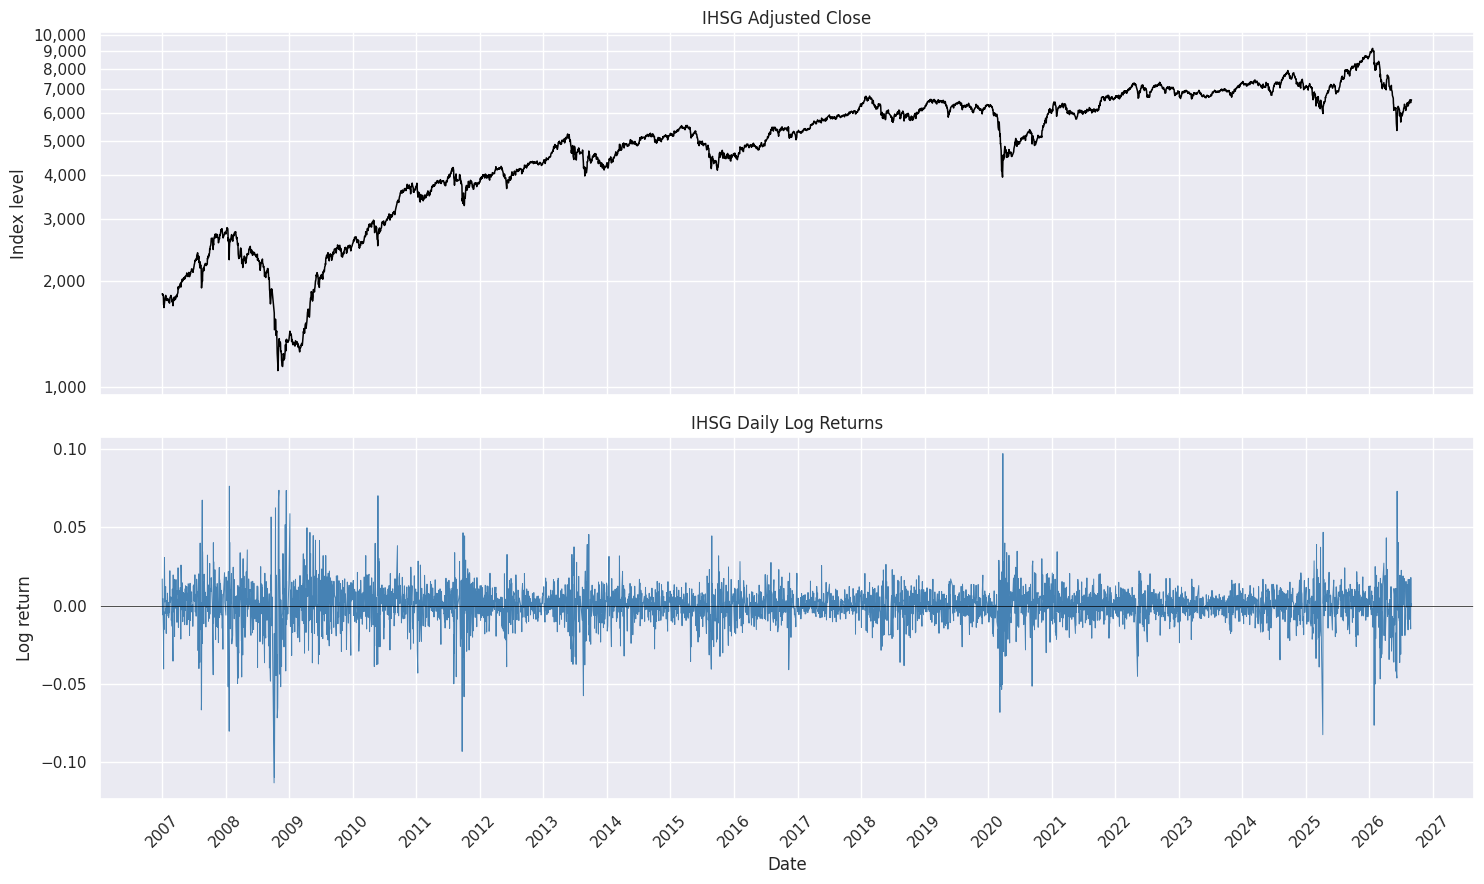

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
axes[0].plot(ihsg_price.index, ihsg_price, color="black", linewidth=1.1)
axes[0].set_title("IHSG Adjusted Close")
axes[0].set_ylabel("Index level")
axes[0].set_yscale("log")
axes[0].set_ylim(bottom=950)
axes[0].yaxis.set_major_locator(
    LogLocator(base=10, subs=(1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0))
)
axes[0].yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: "" if y < 1000 else f"{y:,.0f}")
)

axes[1].plot(log_returns.index, log_returns, color="steelblue", linewidth=0.7)
axes[1].axhline(0, color="black", linewidth=0.7, alpha=0.7)
axes[1].set_title("IHSG Daily Log Returns")
axes[1].set_ylabel("Log return")
axes[1].set_xlabel("Date")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 6. Time-delay embedding and persistent-homology features

For a standardized return series $(z_t)$, the delay-embedded vector is

$$
\mathbf{x}_t = (z_t,z_{t+\tau},\ldots,z_{t+(m-1)\tau}),
$$

where $(m)$ is the embedding dimension and $(\tau)$ is the delay. The primary configuration is $(m=3)$ and $(\tau=1)$. For every rolling window, its embedded vectors form a point cloud in $(\mathbb{R}^3)$.

Vietoris-Rips persistent homology is computed for dimensions $(H_0)$ and $(H_1)$. For each persistence diagram, the notebook calculates the number of finite features, total persistence, mean persistence, maximum persistence, persistence standard deviation, persistence entropy, and an integrated tent-function summary. The same procedure is repeated for each window length in `WINDOWS`.

In [30]:
def delay_embed(values, dimension=EMBEDDING_DIMENSION, delay=EMBEDDING_DELAY):
    """Create a time-delay point cloud from one univariate time series."""
    values = np.asarray(values, dtype=float).reshape(-1)
    if dimension < 1 or delay < 1:
        raise ValueError("Embedding dimension and delay must be positive integers.")
    if not np.isfinite(values).all():
        raise ValueError("The time series passed to delay_embed contains non-finite values.")

    point_count = len(values) - (dimension - 1) * delay
    if point_count < 3:
        raise ValueError("The selected window is too short for the configured delay embedding.")

    return np.column_stack([
        values[offset * delay: offset * delay + point_count]
        for offset in range(dimension)
    ])


def finite_diagram(diagram):
    """Keep persistence pairs with finite birth and death times."""
    diagram = np.asarray(diagram, dtype=float)
    if diagram.size == 0:
        return np.empty((0, 2), dtype=float)
    finite_rows = np.isfinite(diagram).all(axis=1)
    return diagram[finite_rows]


def persistence_features(diagram, prefix):
    """Summarize persistence lifetimes for one homology dimension."""
    diagram = finite_diagram(diagram)
    lifetimes = diagram[:, 1] - diagram[:, 0] if len(diagram) else np.array([])
    lifetimes = lifetimes[np.isfinite(lifetimes) & (lifetimes > 0)]

    if len(lifetimes) == 0:
        return {
            f"{prefix}_n": 0.0,
            f"{prefix}_total": 0.0,
            f"{prefix}_mean": 0.0,
            f"{prefix}_max": 0.0,
            f"{prefix}_std": 0.0,
            f"{prefix}_entropy": 0.0,
            f"{prefix}_landscape_l1": 0.0,
        }

    total = float(lifetimes.sum())
    probabilities = lifetimes / total
    return {
        f"{prefix}_n": float(len(lifetimes)),
        f"{prefix}_total": total,
        f"{prefix}_mean": float(lifetimes.mean()),
        f"{prefix}_max": float(lifetimes.max()),
        f"{prefix}_std": float(lifetimes.std(ddof=0)),
        f"{prefix}_entropy": float(max(0.0, -(probabilities * np.log(probabilities + 1e-15)).sum())),
        f"{prefix}_landscape_l1": float(np.sum(lifetimes ** 2) / 4.0),
    }


def extract_tda_features(point_cloud, window):
    """Extract H0 and H1 persistence summaries from one delay-embedded window."""
    diagrams = ripser(point_cloud, maxdim=1, coeff=2)["dgms"]
    features = {}
    features.update(persistence_features(diagrams[0], f"tda_w{window}_h0"))
    features.update(persistence_features(diagrams[1], f"tda_w{window}_h1"))
    return features

## 7. Index-level financial features

The financial feature set uses only the IHSG series. Each feature is computed on the same rolling window used for TDA. The features include:

- cumulative return, realized volatility, and downside volatility;
- maximum drawdown, mean absolute return, and the fraction of positive-return days;
- average High-Low range as a proportion of Close;
- average intraday log return and overnight log gap;
- mean log-volume level and mean change in log volume.

The volume features describe the index-level `Volume` field returned by Yahoo Finance. They are not built from a collection of individual securities.

In [31]:
def max_drawdown(prices):
    """Calculate the maximum drawdown within one price window."""
    prices = pd.Series(prices, dtype=float).dropna()
    if prices.empty:
        return np.nan
    running_peak = prices.cummax()
    drawdown = prices / running_peak - 1.0
    return float(drawdown.min())


def financial_features(return_window, price_window, ohlcv_window, window):
    """Compute financial features from one IHSG rolling window."""
    returns = pd.Series(return_window, dtype=float).dropna()
    ohlcv = ohlcv_window.reindex(returns.index)
    close = ohlcv["Close"].astype(float)
    open_price = ohlcv["Open"].astype(float)
    high = ohlcv["High"].astype(float)
    low = ohlcv["Low"].astype(float)
    volume = ohlcv["Volume"].astype(float).clip(lower=0)

    downside = np.minimum(returns.to_numpy(), 0.0)
    realized_volatility = float(returns.std(ddof=1) * np.sqrt(252))
    downside_volatility = float(np.sqrt(np.mean(downside ** 2)) * np.sqrt(252))

    price_ratio = (high - low) / close.replace(0, np.nan)
    intraday_log_return = np.log(close / open_price.replace(0, np.nan))
    overnight_gap = np.log(open_price / close.shift(1).replace(0, np.nan))
    log_volume = np.log1p(volume)

    return {
        f"fin_w{window}_cum_return": float(np.expm1(returns.sum())),
        f"fin_w{window}_realized_volatility": realized_volatility,
        f"fin_w{window}_downside_volatility": downside_volatility,
        f"fin_w{window}_max_drawdown": max_drawdown(price_window),
        f"fin_w{window}_mean_abs_return": float(returns.abs().mean()),
        f"fin_w{window}_positive_day_ratio": float((returns > 0).mean()),
        f"fin_w{window}_mean_high_low_range_pct": float(price_ratio.mean()),
        f"fin_w{window}_mean_intraday_log_return": float(intraday_log_return.replace([np.inf, -np.inf], np.nan).mean()),
        f"fin_w{window}_mean_overnight_gap": float(overnight_gap.replace([np.inf, -np.inf], np.nan).mean()),
        f"fin_w{window}_mean_log_volume": float(log_volume.mean()),
        f"fin_w{window}_mean_log_volume_change": float(log_volume.diff().mean()),
    }

## 8. Build the multiscale regime-feature dataset

Each row represents an IHSG market state at `feature_end`. Windows are evaluated at the same endpoint for both representations, and endpoints are sampled every `STRIDE` trading observations. TDA uses the standardized IHSG return window; the financial features use IHSG OHLCV and price/return data. The only inputs are from IHSG.

In [32]:
max_window = max(WINDOWS)
if len(log_returns) < max_window:
    raise ValueError(f"At least {max_window} daily returns are required to construct the rolling windows.")

records = []
for end_pos in range(max_window - 1, len(log_returns), STRIDE):
    end_date = log_returns.index[end_pos]
    row = {
        "feature_end": end_date,
        "is_calibration": end_date <= pd.Timestamp(CALIBRATION_END),
    }

    for window in WINDOWS:
        start_pos = end_pos - window + 1
        window_index = log_returns.index[start_pos:end_pos + 1]
        return_window = log_returns.iloc[start_pos:end_pos + 1]
        tda_window = tda_returns.iloc[start_pos:end_pos + 1]
        price_window = ihsg_price.reindex(window_index)
        ohlcv_window = ihsg_analysis.reindex(window_index)

        point_cloud = delay_embed(tda_window.to_numpy())
        row.update(extract_tda_features(point_cloud, window))
        row.update(financial_features(return_window, price_window, ohlcv_window, window))

    records.append(row)

regime_features = (
    pd.DataFrame(records)
    .sort_values("feature_end")
    .reset_index(drop=True)
)
tda_cols = [column for column in regime_features.columns if column.startswith("tda_")]
financial_cols = [column for column in regime_features.columns if column.startswith("fin_")]

if regime_features.empty or not tda_cols or not financial_cols:
    raise RuntimeError("The regime-feature dataset was not created correctly.")

feature_sets = {
    "Financial": financial_cols,
    "TDA": tda_cols,
    "Financial+TDA": financial_cols + tda_cols,
}

print("Regime-feature rows:", len(regime_features))
print("Financial features:", len(financial_cols))
print("TDA features:", len(tda_cols))
print("Calibration rows:", int(regime_features["is_calibration"].sum()))
print("Test rows:", int((~regime_features["is_calibration"]).sum()))
display(regime_features.head())

Regime-feature rows: 941
Financial features: 33
TDA features: 42
Calibration rows: 524
Test rows: 417


,feature_end,is_calibration,tda_w20_h0_n,tda_w20_h0_total,tda_w20_h0_mean,tda_w20_h0_max,tda_w20_h0_std,tda_w20_h0_entropy,tda_w20_h0_landscape_l1,tda_w20_h1_n,tda_w20_h1_total,tda_w20_h1_mean,tda_w20_h1_max,tda_w20_h1_std,tda_w20_h1_entropy,tda_w20_h1_landscape_l1,fin_w20_cum_return,fin_w20_realized_volatility,fin_w20_downside_volatility,fin_w20_max_drawdown,fin_w20_mean_abs_return,fin_w20_positive_day_ratio,fin_w20_mean_high_low_range_pct,fin_w20_mean_intraday_log_return,fin_w20_mean_overnight_gap,fin_w20_mean_log_volume,fin_w20_mean_log_volume_change,tda_w40_h0_n,tda_w40_h0_total,tda_w40_h0_mean,tda_w40_h0_max,tda_w40_h0_std,tda_w40_h0_entropy,tda_w40_h0_landscape_l1,tda_w40_h1_n,tda_w40_h1_total,tda_w40_h1_mean,tda_w40_h1_max,tda_w40_h1_std,tda_w40_h1_entropy,tda_w40_h1_landscape_l1,fin_w40_cum_return,fin_w40_realized_volatility,fin_w40_downside_volatility,fin_w40_max_drawdown,fin_w40_mean_abs_return,fin_w40_positive_day_ratio,fin_w40_mean_high_low_range_pct,fin_w40_mean_intraday_log_return,fin_w40_mean_overnight_gap,fin_w40_mean_log_volume,fin_w40_mean_log_volume_change,tda_w60_h0_n,tda_w60_h0_total,tda_w60_h0_mean,tda_w60_h0_max,tda_w60_h0_std,tda_w60_h0_entropy,tda_w60_h0_landscape_l1,tda_w60_h1_n,tda_w60_h1_total,tda_w60_h1_mean,tda_w60_h1_max,tda_w60_h1_std,tda_w60_h1_entropy,tda_w60_h1_landscape_l1,fin_w60_cum_return,fin_w60_realized_volatility,fin_w60_downside_volatility,fin_w60_max_drawdown,fin_w60_mean_abs_return,fin_w60_positive_day_ratio,fin_w60_mean_high_low_range_pct,fin_w60_mean_intraday_log_return,fin_w60_mean_overnight_gap,fin_w60_mean_log_volume,fin_w60_mean_log_volume_change
0,2007-03-27,True,17.0,15.837054,0.931591,1.497653,0.366452,2.753262,4.259136,2.0,0.173020,0.086510,0.145307,0.058797,0.439956,0.005471,0.020017,0.212247,0.157209,-0.036955,0.009647,0.65,0.013221,0.002381,-0.001603,16.892574,-0.027334,37.0,23.665550,0.639609,1.485698,0.323335,3.491540,4.751224,5.0,0.575316,0.115063,0.171475,0.059618,1.447237,0.020992,0.030972,0.171719,0.120342,-0.064818,0.007845,0.575,0.011409,0.000871,-0.000207,16.879615,0.003936,57.0,40.254935,0.706227,2.110803,0.457609,3.868659,10.091312,19.0,1.927607,0.101453,0.354381,0.094621,2.535438,0.091418,0.007830,0.197944,0.145796,-0.086292,0.009099,0.533333,0.012786,0.000199,-0.000144,16.833684,-0.004483
1,2007-04-03,True,17.0,13.260274,0.780016,1.144059,0.201590,2.797202,2.758521,3.0,0.280896,0.093632,0.131719,0.033153,1.032099,0.007400,0.115231,0.166838,0.081185,-0.019538,0.009196,0.75,0.010568,0.003337,0.001734,16.828245,0.000624,37.0,25.100576,0.678394,1.485698,0.301778,3.515001,5.099414,12.0,0.973117,0.081093,0.195756,0.062915,2.188273,0.031603,0.071266,0.184236,0.121560,-0.064818,0.008768,0.600,0.011575,0.001899,-0.000126,16.894494,0.010573,57.0,38.486230,0.675197,2.110803,0.418950,3.885128,8.997591,21.0,1.983313,0.094443,0.358220,0.089682,2.650313,0.089053,0.044768,0.202782,0.145339,-0.065252,0.009477,0.566667,0.012981,0.000622,0.000036,16.846757,0.051560
2,2007-04-11,True,17.0,13.715784,0.806811,1.688518,0.327302,2.753631,3.221798,1.0,0.258143,0.258143,0.258143,0.000000,0.000000,0.016660,0.076077,0.161992,0.093875,-0.019538,0.008400,0.75,0.009765,0.001573,0.002085,16.816059,0.011202,37.0,27.261348,0.736793,1.485698,0.310890,3.519986,5.915529,10.0,1.017837,0.101784,0.329059,0.101100,1.811374,0.051453,0.113339,0.188292,0.123212,-0.064818,0.009348,0.675,0.011632,0.001674,0.001040,16.889291,0.013992,57.0,33.685563,0.590975,1.485698,0.280712,3.942059,6.099721,20.0,2.014653,0.100733,0.264807,0.076602,2.679727,0.080075,0.115904,0.170935,0.112518,-0.065252,0.008451,0.616667,0.011424,0.001414,0.000310,16.882633,0.005155
3,2007-04-18,True,17.0,12.202222,0.717778,1.576325,0.324893,2.739056,2.638231,2.0,0.322246,0.161123,0.258143,0.097020,0.498908,0.017687,0.103780,0.139965,0.063187,-0.013756,0.007886,0.75,0.009431,0.002276,0.002793,16.933734,0.023033,37.0,25.871302,0.699224,1.485698,0.331895,3.502431,5.541391,8.0,0.821208,0.102651,0.329059,0.092770,1.753303,0.038287,0.089137,

## 9. Define reference drawdown events for evaluation

A reference event starts when the price drawdown from the running peak exceeds both an absolute threshold and a volatility-scaled threshold. The event is treated as recovered when price returns to within `CRISIS_RECOVERY_LEVEL` of its peak. The trigger dates are used to evaluate regime timing, but they are not included in the Financial or TDA feature matrices and do not affect K-Means fitting.

In [33]:
def detect_drawdown_events(
    prices,
    returns,
    vol_window=20,
    vol_horizon=20,
    kappa=2.0,
    min_abs_drawdown=0.10,
    recovery_level=0.05,
):
    """Detect volatility-scaled drawdown events in the IHSG index series."""
    prices = pd.Series(prices).dropna().sort_index()
    returns = pd.Series(returns).reindex(prices.index)
    rolling_volatility = returns.rolling(vol_window).std()

    event_columns = [
        "peak_date", "peak_price", "trigger_date", "trigger_drawdown",
        "trigger_volatility", "vol_adjusted_drawdown", "trough_date",
        "trough_price", "max_drawdown", "recovery_date",
    ]
    events = []
    peak_price = -np.inf
    peak_date = None
    in_event = False
    event = None

    for date, price_value in prices.items():
        price_value = float(price_value)
        sigma = rolling_volatility.loc[date]
        if pd.isna(sigma) or sigma <= 0:
            continue

        if not in_event:
            if price_value >= peak_price:
                peak_price = price_value
                peak_date = date
            drawdown = price_value / peak_price - 1.0
            volatility_scale = float(sigma) * np.sqrt(vol_horizon)
            scaled_drawdown = -drawdown / volatility_scale

            if -drawdown >= min_abs_drawdown and scaled_drawdown >= kappa:
                in_event = True
                event = {
                    "peak_date": peak_date,
                    "peak_price": peak_price,
                    "trigger_date": date,
                    "trigger_drawdown": drawdown,
                    "trigger_volatility": float(sigma),
                    "vol_adjusted_drawdown": scaled_drawdown,
                    "trough_date": date,
                    "trough_price": price_value,
                    "max_drawdown": drawdown,
                    "recovery_date": pd.NaT,
                }
        else:
            drawdown = price_value / event["peak_price"] - 1.0
            if price_value < event["trough_price"]:
                event["trough_price"] = price_value
                event["trough_date"] = date
                event["max_drawdown"] = drawdown
            if drawdown >= -recovery_level:
                event["recovery_date"] = date
                events.append(event)
                in_event = False
                peak_price = price_value
                peak_date = date
                event = None

    if in_event and event is not None:
        events.append(event)

    return pd.DataFrame(events, columns=event_columns)


critical_events = detect_drawdown_events(
    prices=ihsg_price,
    returns=log_returns,
    vol_window=CRISIS_VOL_WINDOW,
    vol_horizon=CRISIS_VOL_HORIZON,
    kappa=CRISIS_VOL_DRAWDOWN_KAPPA,
    min_abs_drawdown=CRISIS_MIN_ABS_DRAWDOWN,
    recovery_level=CRISIS_RECOVERY_LEVEL,
)
critical_events["sample"] = np.where(
    critical_events["trigger_date"] <= pd.Timestamp(CALIBRATION_END),
    "Calibration",
    "Test",
)

print("Reference drawdown events detected:", len(critical_events))
display(critical_events)

Reference drawdown events detected: 12


,peak_date,peak_price,trigger_date,trigger_drawdown,trigger_volatility,vol_adjusted_drawdown,trough_date,trough_price,max_drawdown,recovery_date,sample
0,2008-01-09,2830.152832,2008-03-17,-0.183001,0.018585,2.201794,2008-10-28,1111.346802,-0.607319,2010-03-17,Calibration
1,2011-08-01,4193.277832,2011-11-25,-0.132647,0.014349,2.067075,2011-11-25,3637.050049,-0.132647,2012-01-19,Calibration
2,2012-05-03,4223.838867,2012-06-01,-0.100435,0.010189,2.204069,2012-06-04,3654.439697,-0.134806,2012-07-03,Calibration
3,2013-05-20,5214.772949,2013-08-12,-0.118351,0.010971,2.412285,2013-08-27,3967.687744,-0.239145,2014-05-14,Calibration
4,2015-04-07,5523.074707,2015-06-09,-0.112869,0.008643,2.919984,2015-09-28,4120.342285,-0.253977,2016-07-27,Calibration
5,2018-02-19,6689.287109,2018-04-26,-0.116618,0.010999,2.370833,2018-07-03,5633.937012,-0.157767,2019-01-11,Test
6,2019-02-06,6547.876953,2019-05-17,-0.110113,0.008141,3.024601,2019-05-17,5826.868164,-0.110113,2019-06-10,Test
7,2019-07-19,6456.539062,2020-02-24,-0.100594,0.007450,3.019342,2020-03-24,3937.632080,-0.390133,2020-12-21,Test
8,2021-01-13,6435.205078,2021-05-19,-0.104833,0.006399,3.663115,2021-05-19,5760.583984,-0.104833,2021-07-22,Test
9,2022-09-13,7318.016113,2023-01-11,-0.100241,0.008413,2.664392,2023-03-16,6565.728027,-0.102799,2023-08-29,Test


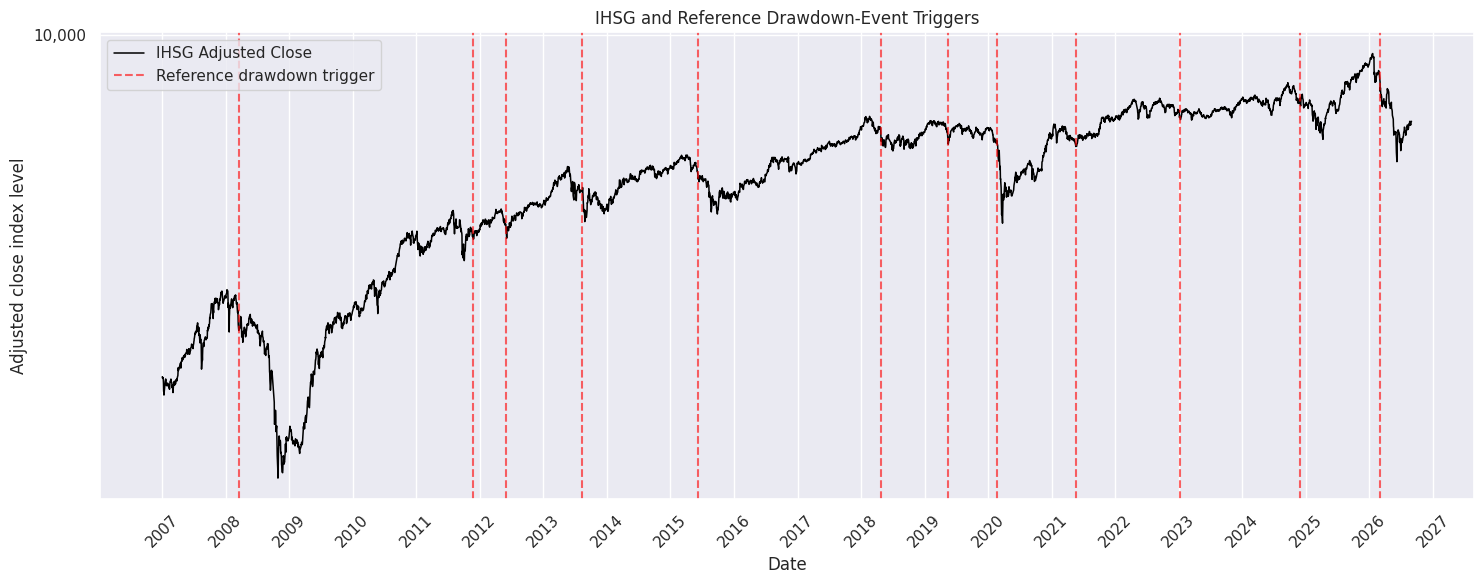

In [34]:
def format_year_axis(axis, interval=1):
    """Format a time-series axis with calendar-year ticks."""
    axis.xaxis.set_major_locator(mdates.YearLocator(interval))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axis.tick_params(axis="x", rotation=45)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(ihsg_price.index, ihsg_price, linewidth=1.1, color="black", label="IHSG Adjusted Close")
for event_index, event in critical_events.iterrows():
    ax.axvline(
        event["trigger_date"], color="red", linestyle="--", alpha=0.6,
        label="Reference drawdown trigger" if event_index == critical_events.index[0] else None,
    )
ax.set_title("IHSG and Reference Drawdown-Event Triggers")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted close index level")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
format_year_axis(ax)
ax.legend()
plt.tight_layout()
plt.show()

## 10. Mark pre-event evaluation windows

A feature endpoint is marked as pre-critical if it occurs between one and `PRECRITICAL_LOOKBACK` trading observations before a reference drawdown trigger. This flag is used only for post-clustering evaluation.

In [35]:
def mark_precritical(feature_dates, event_dates, trading_index, lookback=20):
    trading_index = pd.DatetimeIndex(trading_index)
    position = {pd.Timestamp(date): index for index, date in enumerate(trading_index)}
    event_positions = [
        position[pd.Timestamp(date)]
        for date in event_dates
        if pd.notna(date) and pd.Timestamp(date) in position
    ]

    flags = []
    for date in pd.to_datetime(feature_dates):
        if date not in position:
            flags.append(False)
            continue
        current_position = position[date]
        flags.append(any(1 <= event_position - current_position <= lookback for event_position in event_positions))
    return np.asarray(flags, dtype=bool)


regime_features["is_precritical"] = mark_precritical(
    regime_features["feature_end"],
    critical_events["trigger_date"],
    ihsg_price.index,
    lookback=PRECRITICAL_LOOKBACK,
)
display(regime_features[["feature_end", "is_calibration", "is_precritical"]].head())

,feature_end,is_calibration,is_precritical
0,2007-03-27,True,False
1,2007-04-03,True,False
2,2007-04-11,True,False
3,2007-04-18,True,False
4,2007-04-25,True,False


## 11. K-Means model selection and out-of-sample assignment

All feature spaces use the same chronology:

1. Fit the scaler on calibration rows only.
2. Evaluate candidate $(k)$ values on the scaled calibration features.
3. Fit the primary K-Means model using the pre-specified analysis value of $(k)$.
4. Predict cluster assignments for test rows using the fitted scaler and fixed calibration centroids.

Candidate cluster counts are ranked using Silhouette Score, Calinski-Harabasz Score, Davies-Bouldin Score, and cluster stability based on pairwise adjusted Rand indices across random seeds. The primary Financial-versus-TDA comparison remains fixed at $(k=2)$ for interpretability and consistency.

In [36]:
def make_scaler(kind=SCALER_KIND):
    if kind == "standard":
        return StandardScaler()
    if kind == "robust":
        return RobustScaler(quantile_range=(20.0, 80.0))
    if kind == "minmax":
        return MinMaxScaler()
    raise ValueError("SCALER_KIND must be 'standard', 'robust', or 'minmax'.")


def kmeans_stability(features, cluster_count, seeds=STABILITY_SEEDS):
    label_runs = []
    for seed in seeds:
        model = KMeans(
            n_clusters=cluster_count,
            init="k-means++",
            n_init=1,
            random_state=seed,
        )
        label_runs.append(model.fit_predict(features))
    scores = [adjusted_rand_score(first, second) for first, second in combinations(label_runs, 2)]
    return float(np.mean(scores)) if scores else np.nan


def evaluate_k_values(features, k_values=K_VALUES):
    rows = []
    for cluster_count in k_values:
        if cluster_count >= len(features):
            continue
        model = KMeans(n_clusters=cluster_count, n_init=KMEANS_N_INIT, random_state=SEED)
        labels = model.fit_predict(features)
        unique_labels = np.unique(labels)
        if 1 < len(unique_labels) < len(features):
            silhouette = silhouette_score(features, labels)
            calinski = calinski_harabasz_score(features, labels)
            davies = davies_bouldin_score(features, labels)
        else:
            silhouette, calinski, davies = np.nan, np.nan, np.nan
        rows.append({
            "k": cluster_count,
            "silhouette": silhouette,
            "calinski_harabasz": calinski,
            "davies_bouldin": davies,
            "stability_ari": kmeans_stability(features, cluster_count),
            "inertia": model.inertia_,
        })

    metrics = pd.DataFrame(rows)
    if metrics.empty:
        raise ValueError("There are too few calibration rows to evaluate the requested cluster counts.")
    metrics["rank_silhouette"] = metrics["silhouette"].rank(ascending=False)
    metrics["rank_calinski"] = metrics["calinski_harabasz"].rank(ascending=False)
    metrics["rank_davies"] = metrics["davies_bouldin"].rank(ascending=True)
    metrics["rank_stability"] = metrics["stability_ari"].rank(ascending=False)
    metrics["mean_rank"] = metrics[[
        "rank_silhouette", "rank_calinski", "rank_davies", "rank_stability"
    ]].mean(axis=1)
    return metrics.sort_values(["mean_rank", "silhouette"], ascending=[True, False]).reset_index(drop=True)


def fit_regime_model(features_df, feature_columns, analysis_k):
    calibration_mask = features_df["is_calibration"].to_numpy(dtype=bool)
    feature_matrix = features_df[feature_columns].replace([np.inf, -np.inf], np.nan)
    if feature_matrix.isna().any().any():
        missing = feature_matrix.columns[feature_matrix.isna().any()].tolist()
        raise ValueError(f"Missing or non-finite values found in features: {missing}")

    calibration_raw = feature_matrix.loc[calibration_mask].to_numpy(dtype=float)
    test_raw = feature_matrix.loc[~calibration_mask].to_numpy(dtype=float)
    if len(calibration_raw) <= analysis_k:
        raise ValueError(f"The calibration sample is too small for k={analysis_k}.")

    scaler = make_scaler(SCALER_KIND)
    calibration_scaled = scaler.fit_transform(calibration_raw)
    test_scaled = scaler.transform(test_raw) if len(test_raw) else np.empty((0, calibration_scaled.shape[1]))
    k_metrics = evaluate_k_values(calibration_scaled)
    recommended_k = int(k_metrics.iloc[0]["k"])

    model = KMeans(n_clusters=analysis_k, n_init=KMEANS_N_INIT, random_state=SEED)
    calibration_labels = model.fit_predict(calibration_scaled)
    test_labels = model.predict(test_scaled) if len(test_scaled) else np.array([], dtype=int)
    all_labels = np.empty(len(features_df), dtype=int)
    all_labels[calibration_mask] = calibration_labels
    all_labels[~calibration_mask] = test_labels

    return {
        "scaler": scaler,
        "model": model,
        "recommended_k": recommended_k,
        "analysis_k": analysis_k,
        "k_metrics": k_metrics,
        "labels": all_labels,
        "calibration_scaled": calibration_scaled,
        "test_scaled": test_scaled,
    }


regime_models = {}
for feature_name, columns in feature_sets.items():
    regime_models[feature_name] = fit_regime_model(
        regime_features,
        columns,
        analysis_k=ANALYSIS_K[feature_name],
    )
    result = regime_models[feature_name]
    print(
        f"{feature_name}: recommended k={result['recommended_k']}, "
        f"analysis k={result['analysis_k']}"
    )

Financial: recommended k=2, analysis k=2
TDA: recommended k=3, analysis k=2
Financial+TDA: recommended k=3, analysis k=3


In [37]:
for feature_name, result in regime_models.items():
    print(f"\n{feature_name} cluster-count evaluation")
    display(result["k_metrics"][[
        "k", "silhouette", "calinski_harabasz", "davies_bouldin", "stability_ari", "mean_rank"
    ]].round(4))

ranking_rows = []
for feature_name, result in regime_models.items():
    ranking_rows.append(
        result["k_metrics"].nsmallest(2, "mean_rank").assign(feature_set=feature_name)
    )
model_ranking = pd.concat(ranking_rows, ignore_index=True)
display(model_ranking[[
    "feature_set", "k", "silhouette", "calinski_harabasz", "davies_bouldin", "stability_ari", "mean_rank"
]].round(4))


Financial cluster-count evaluation


,k,silhouette,calinski_harabasz,davies_bouldin,stability_ari,mean_rank
0,2,0.7062,200.5655,0.6111,1.0000,1.00
1,4,0.3252,171.2376,1.3034,0.9376,3.25
2,3,0.3151,197.3586,1.1999,0.5037,3.25
3,5,0.3327,159.7013,1.0365,0.4612,3.75
4,6,0.2133,150.5237,1.2959,0.4854,5.00
5,8,0.1596,136.7143,1.3146,0.6806,5.50
6,7,0.1569,141.7306,1.3973,0.4998,6.25



TDA cluster-count evaluation


,k,silhouette,calinski_harabasz,davies_bouldin,stability_ari,mean_rank
0,3,0.4709,343.0272,0.9319,0.9499,1.75
1,4,0.4044,301.7915,1.0528,0.9796,2.25
2,2,0.9006,289.6177,0.2547,0.4128,3.00
3,5,0.3662,272.6408,1.1606,0.6135,4.25
4,7,0.1901,231.1302,1.3166,0.6872,4.75
5,6,0.1870,248.5736,1.3787,0.6642,5.50
6,8,0.1826,217.1576,1.3210,0.5730,6.50



Financial+TDA cluster-count evaluation


,k,silhouette,calinski_harabasz,davies_bouldin,stability_ari,mean_rank
0,3,0.4255,215.6624,1.0699,0.8014,2.00
1,4,0.3244,206.4062,1.1711,0.8706,2.50
2,2,0.7487,184.0248,0.9614,0.3331,3.00
3,6,0.1770,162.0524,1.3881,0.8728,4.25
4,8,0.2089,140.3773,1.3122,0.6020,5.25
5,7,0.1848,150.4274,1.4458,0.6666,5.50
6,5,0.1723,178.1452,1.5669,0.7655,5.50


,feature_set,k,silhouette,calinski_harabasz,davies_bouldin,stability_ari,mean_rank
0,Financial,2,0.7062,200.5655,0.6111,1.0000,1.00
1,Financial,4,0.3252,171.2376,1.3034,0.9376,3.25
2,TDA,3,0.4709,343.0272,0.9319,0.9499,1.75
3,TDA,4,0.4044,301.7915,1.0528,0.9796,2.25
4,Financial+TDA,3,0.4255,215.6624,1.0699,0.8014,2.00
5,Financial+TDA,4,0.3244,206.4062,1.1711,0.8706,2.50


## 12. Assign semantic regime labels and inspect cluster profiles

Cluster IDs are arbitrary, so the labels `Baseline`, `Stress`, and, for the exploratory three-cluster model, `Extreme Stress` are assigned using a financial-stress index. That index combines calibration-standardized financial indicators: volatility, downside volatility, mean absolute return, drawdown, and cumulative return. Drawdown and cumulative return are direction-adjusted so higher values consistently indicate greater stress.

The mapping is learned from calibration clusters and is then held fixed for the test period. For TDA clusters, the stress index is an external descriptor for interpretation, not an input to the TDA clustering model.

In [38]:
financial_stress_columns = [
    column for column in financial_cols
    if any(token in column for token in [
        "realized_volatility", "downside_volatility", "mean_abs_return", "max_drawdown", "cum_return"
    ])
]

financial_stress_raw = regime_features[financial_stress_columns].copy()
stress_mean = financial_stress_raw.loc[regime_features["is_calibration"]].mean()
stress_std = financial_stress_raw.loc[regime_features["is_calibration"]].std(ddof=1).replace(0, 1.0)
stress_z = (financial_stress_raw - stress_mean) / stress_std
stress_direction = pd.Series(1.0, index=financial_stress_columns)
stress_direction[[column for column in financial_stress_columns if "max_drawdown" in column]] = -1.0
stress_direction[[column for column in financial_stress_columns if "cum_return" in column]] = -1.0
financial_stress_index = stress_z.mul(stress_direction, axis=1).mean(axis=1)

financial_regime_df = regime_features.copy()
tda_regime_df = regime_features.copy()
combined_regime_df = regime_features.copy()
financial_regime_df["cluster"] = regime_models["Financial"]["labels"]
tda_regime_df["cluster"] = regime_models["TDA"]["labels"]
combined_regime_df["cluster"] = regime_models["Financial+TDA"]["labels"]
for regime_df in [financial_regime_df, tda_regime_df, combined_regime_df]:
    regime_df["financial_stress_index"] = financial_stress_index.to_numpy()


def assign_semantic_regimes(regime_df):
    calibration = regime_df.loc[regime_df["is_calibration"]]
    stress_order = (
        calibration.groupby("cluster")["financial_stress_index"]
        .mean()
        .sort_values()
        .index.tolist()
    )
    if len(stress_order) == 2:
        labels = {stress_order[0]: "Baseline", stress_order[1]: "Stress"}
    elif len(stress_order) == 3:
        labels = {
            stress_order[0]: "Baseline",
            stress_order[1]: "Stress",
            stress_order[2]: "Extreme Stress",
        }
    else:
        labels = {cluster_id: f"Regime {position + 1}" for position, cluster_id in enumerate(stress_order)}
    labeled = regime_df.copy()
    labeled["regime_label"] = labeled["cluster"].map(labels)
    return labeled, labels


financial_regime_df, financial_label_map = assign_semantic_regimes(financial_regime_df)
tda_regime_df, tda_label_map = assign_semantic_regimes(tda_regime_df)
combined_regime_df, combined_label_map = assign_semantic_regimes(combined_regime_df)

print("Financial cluster mapping:", financial_label_map)
print("TDA cluster mapping:", tda_label_map)
print("Exploratory Financial+TDA cluster mapping:", combined_label_map)

profile_cols = [
    column for column in (financial_cols + tda_cols)
    if any(token in column for token in [
        "cum_return", "realized_volatility", "downside_volatility", "max_drawdown",
        "mean_abs_return", "_total", "_max", "_entropy"
    ])
]
if "financial_stress_index" not in profile_cols:
    profile_cols.append("financial_stress_index")


def cluster_profile_table(regime_df):
    profile = regime_df.groupby(["cluster", "regime_label"])[profile_cols].mean()
    size = regime_df.groupby(["cluster", "regime_label"]).size().rename("n")
    return profile.join(size)


financial_cluster_profile = cluster_profile_table(financial_regime_df)
tda_cluster_profile = cluster_profile_table(tda_regime_df)
combined_cluster_profile = cluster_profile_table(combined_regime_df)

print("Financial regime profiles")
display(financial_cluster_profile.round(4))
print("TDA regime profiles")
display(tda_cluster_profile.round(4))
print("Exploratory Financial+TDA regime profiles")
display(combined_cluster_profile.round(4))

Financial cluster mapping: {0: 'Baseline', 1: 'Stress'}
TDA cluster mapping: {0: 'Baseline', 1: 'Stress'}
Exploratory Financial+TDA cluster mapping: {0: 'Baseline', 1: 'Stress', 2: 'Extreme Stress'}
Financial regime profiles


,,fin_w20_cum_return,fin_w20_realized_volatility,fin_w20_downside_volatility,fin_w20_max_drawdown,fin_w20_mean_abs_return,fin_w40_cum_return,fin_w40_realized_volatility,fin_w40_downside_volatility,fin_w40_max_drawdown,fin_w40_mean_abs_return,fin_w60_cum_return,fin_w60_realized_volatility,fin_w60_downside_volatility,fin_w60_max_drawdown,fin_w60_mean_abs_return,tda_w20_h0_total,tda_w20_h0_max,tda_w20_h0_entropy,tda_w20_h1_total,tda_w20_h1_max,tda_w20_h1_entropy,tda_w40_h0_total,tda_w40_h0_max,tda_w40_h0_entropy,tda_w40_h1_total,tda_w40_h1_max,tda_w40_h1_entropy,tda_w60_h0_total,tda_w60_h0_max,tda_w60_h0_entropy,tda_w60_h1_total,tda_w60_h1_max,tda_w60_h1_entropy,financial_stress_index,n
cluster,regime_label,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,Baseline,0.010,0.1640,0.1130,-0.0413,0.0081,0.0200,0.1687,0.1182,-0.0627,0.0081,0.0288,0.1721,0.1217,-0.0797,0.0082,13.3469,1.5072,2.7384,0.316,0.1790,0.7333,23.1529,1.6245,3.4813,0.8415,0.2424,1.8115,31.7792,1.7445,3.8904,1.3668,0.2610,2.3928,-0.1327,924
1,Stress,-0.145,0.5682,0.4606,-0.2307,0.0284,-0.2756,0.5249,0.4466,-0.3542,0.0249,-0.3412,0.4632,0.3995,-0.4099,0.0209,45.7446,5.1304,2.7558,1.250,0.7319,0.6369,71.1035,5.2939,3.4529,2.6119,0.7039,1.8399,83.1461,5.4948,3.7954,3.0621,0.7276,2.2070,3.3618,17


TDA regime profiles


,,fin_w20_cum_return,fin_w20_realized_volatility,fin_w20_downside_volatility,fin_w20_max_drawdown,fin_w20_mean_abs_return,fin_w40_cum_return,fin_w40_realized_volatility,fin_w40_downside_volatility,fin_w40_max_drawdown,fin_w40_mean_abs_return,fin_w60_cum_return,fin_w60_realized_volatility,fin_w60_downside_volatility,fin_w60_max_drawdown,fin_w60_mean_abs_return,tda_w20_h0_total,tda_w20_h0_max,tda_w20_h0_entropy,tda_w20_h1_total,tda_w20_h1_max,tda_w20_h1_entropy,tda_w40_h0_total,tda_w40_h0_max,tda_w40_h0_entropy,tda_w40_h1_total,tda_w40_h1_max,tda_w40_h1_entropy,tda_w60_h0_total,tda_w60_h0_max,tda_w60_h0_entropy,tda_w60_h1_total,tda_w60_h1_max,tda_w60_h1_entropy,financial_stress_index,n
cluster,regime_label,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,Baseline,0.0074,0.1703,0.1185,-0.0443,0.0084,0.0154,0.1741,0.1232,-0.0672,0.0084,0.0230,0.1766,0.1260,-0.0848,0.0084,13.8466,1.5662,2.7387,0.3246,0.1852,0.7308,23.8732,1.6817,3.4807,0.8634,0.2481,1.8115,32.5582,1.8034,3.8888,1.3901,0.2669,2.3904,-0.0789,939
1,Stress,-0.1080,0.6817,0.5024,-0.2570,0.0343,-0.3463,0.6739,0.5779,-0.4345,0.0327,-0.3938,0.5706,0.4909,-0.4907,0.0263,54.1133,4.6466,2.7704,4.2052,1.9770,1.1224,92.5667,5.9479,3.4905,5.6091,1.4773,2.0652,102.6615,5.9479,3.8367,4.8202,1.4773,1.9224,4.2955,2


Exploratory Financial+TDA regime profiles


,,fin_w20_cum_return,fin_w20_realized_volatility,fin_w20_downside_volatility,fin_w20_max_drawdown,fin_w20_mean_abs_return,fin_w40_cum_return,fin_w40_realized_volatility,fin_w40_downside_volatility,fin_w40_max_drawdown,fin_w40_mean_abs_return,fin_w60_cum_return,fin_w60_realized_volatility,fin_w60_downside_volatility,fin_w60_max_drawdown,fin_w60_mean_abs_return,tda_w20_h0_total,tda_w20_h0_max,tda_w20_h0_entropy,tda_w20_h1_total,tda_w20_h1_max,tda_w20_h1_entropy,tda_w40_h0_total,tda_w40_h0_max,tda_w40_h0_entropy,tda_w40_h1_total,tda_w40_h1_max,tda_w40_h1_entropy,tda_w60_h0_total,tda_w60_h0_max,tda_w60_h0_entropy,tda_w60_h1_total,tda_w60_h1_max,tda_w60_h1_entropy,financial_stress_index,n
cluster,regime_label,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,Baseline,0.0121,0.1390,0.0943,-0.0333,0.0069,0.0253,0.1430,0.0986,-0.0491,0.0070,0.0361,0.1482,0.1031,-0.0628,0.0072,11.2682,1.2575,2.7409,0.2725,0.1518,0.7392,19.5309,1.3197,3.4877,0.7277,0.2085,1.8176,27.2558,1.4281,3.8995,1.1930,0.2266,2.3950,-0.3203,793
1,Stress,-0.0179,0.3401,0.2496,-0.1041,0.0164,-0.0380,0.3433,0.2572,-0.1653,0.0160,-0.0481,0.3305,0.2500,-0.2044,0.0151,27.8513,3.2429,2.7263,0.6075,0.3669,0.6850,47.4584,3.6477,3.4429,1.6006,0.4638,1.7779,61.3581,3.8421,3.8306,2.4611,0.4858,2.3654,1.2322,146
2,Extreme Stress,-0.1080,0.6817,0.5024,-0.2570,0.0343,-0.3463,0.6739,0.5779,-0.4345,0.0327,-0.3938,0.5706,0.4909,-0.4907,0.0263,54.1133,4.6466,2.7704,4.2052,1.9770,1.1224,92.5667,5.9479,3.4905,5.6091,1.4773,2.0652,102.6615,5.9479,3.8367,4.8202,1.4773,1.9224,4.2955,2


## 13. PCA visualizations

PCA is used only to visualize the clusters. It does not determine the cluster assignments. The PCA transformation is fitted on calibration observations and then applied to the complete feature sequence.

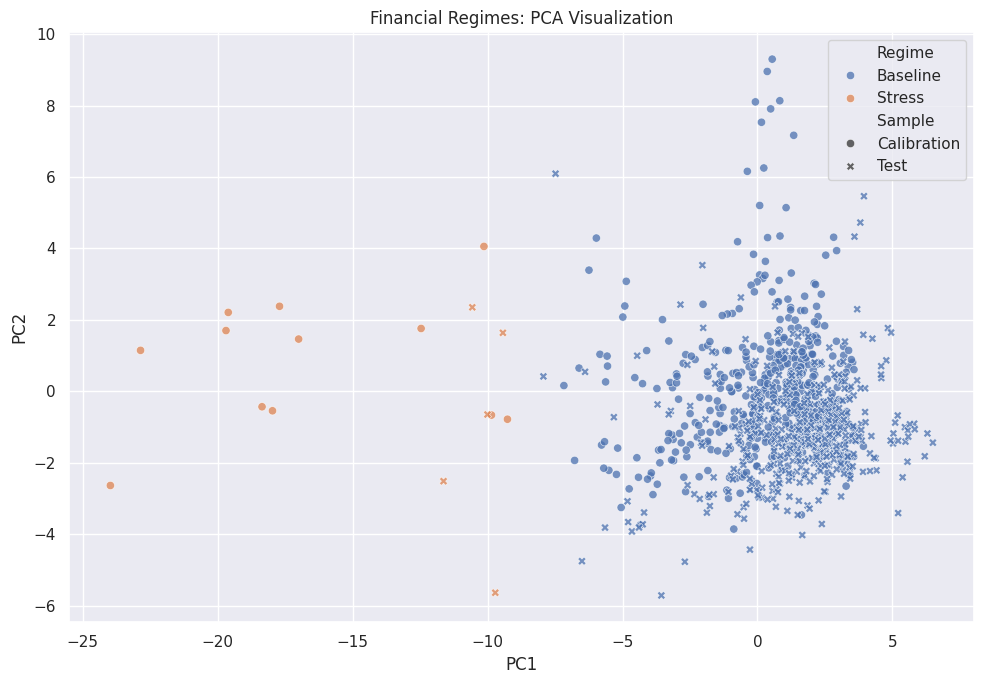

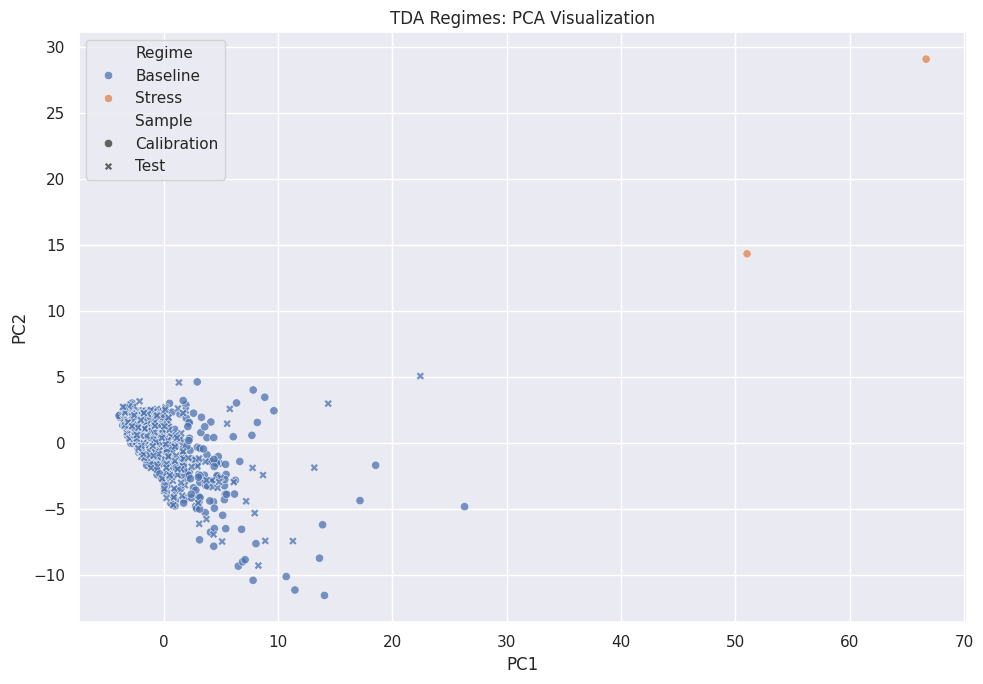

In [39]:
def plot_regime_pca(feature_name, regime_df, feature_columns):
    result = regime_models[feature_name]
    calibration_mask = regime_df["is_calibration"].to_numpy(dtype=bool)
    raw_matrix = regime_df[feature_columns].to_numpy(dtype=float)
    scaled_matrix = result["scaler"].transform(raw_matrix)

    pca = PCA(n_components=2, random_state=SEED)
    pca.fit(scaled_matrix[calibration_mask])
    coordinates = pca.transform(scaled_matrix)
    pca_frame = pd.DataFrame({
        "PC1": coordinates[:, 0],
        "PC2": coordinates[:, 1],
        "Regime": regime_df["regime_label"].to_numpy(),
        "Sample": np.where(calibration_mask, "Calibration", "Test"),
    })

    fig, ax = plt.subplots(figsize=(10, 7))
    sns.scatterplot(
        data=pca_frame, x="PC1", y="PC2", hue="Regime", style="Sample",
        alpha=0.75, ax=ax,
    )
    ax.set_title(f"{feature_name} Regimes: PCA Visualization")
    plt.tight_layout()
    plt.show()


plot_regime_pca("Financial", financial_regime_df, financial_cols)
plot_regime_pca("TDA", tda_regime_df, tda_cols)

In [46]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


def plot_regime_pca_3d(feature_name, regime_df, feature_columns):
    result = regime_models[feature_name]

    calibration_mask = regime_df["is_calibration"].to_numpy(dtype=bool)
    raw_matrix = regime_df[feature_columns].to_numpy(dtype=float)

    # Transform features using the fitted scaler
    scaled_matrix = result["scaler"].transform(raw_matrix)

    # Fit PCA using calibration data only
    pca = PCA(n_components=3, random_state=SEED)
    pca.fit(scaled_matrix[calibration_mask])

    # Project all observations into the 3D PCA space
    coordinates = pca.transform(scaled_matrix)

    pca_frame = pd.DataFrame({
        "PC1": coordinates[:, 0],
        "PC2": coordinates[:, 1],
        "PC3": coordinates[:, 2],
        "Regime": regime_df["regime_label"].to_numpy(),
        "Sample": np.where(
            calibration_mask, "Calibration", "Test"
        ),
    })

    # Create the 3D scatter plot
    fig = plt.figure(figsize=(12, 9))
    ax = fig.add_subplot(111, projection="3d")

    regimes = pca_frame["Regime"].unique()
    colors = sns.color_palette("husl", n_colors=len(regimes))
    color_map = dict(zip(regimes, colors))

    markers = {
        "Calibration": "o",
        "Test": "^",
    }

    for regime in regimes:
        for sample in ["Calibration", "Test"]:
            subset = pca_frame[
                (pca_frame["Regime"] == regime)
                & (pca_frame["Sample"] == sample)
            ]

            if subset.empty:
                continue

            ax.scatter(
                subset["PC1"],
                subset["PC2"],
                subset["PC3"],
                color=color_map[regime],
                marker=markers[sample],
                alpha=0.7,
                s=35,
                label=f"{regime} | {sample}",
            )

    ax.set_title(f"{feature_name} Regimes: 3D PCA Visualization")
    ax.set_xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)"
    )
    ax.set_ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)"
    )
    ax.set_zlabel(
        f"PC3 ({pca.explained_variance_ratio_[2] * 100:.2f}%)"
    )

    ax.legend(
        title="Regime | Sample",
        bbox_to_anchor=(1.25, 1),
        loc="upper left",
    )

    plt.tight_layout()
    plt.show()

    # Report the total variance explained by the three components
    print(
        f"{feature_name} 3D PCA total explained variance: "
        f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
    )

    return pca, pca_frame


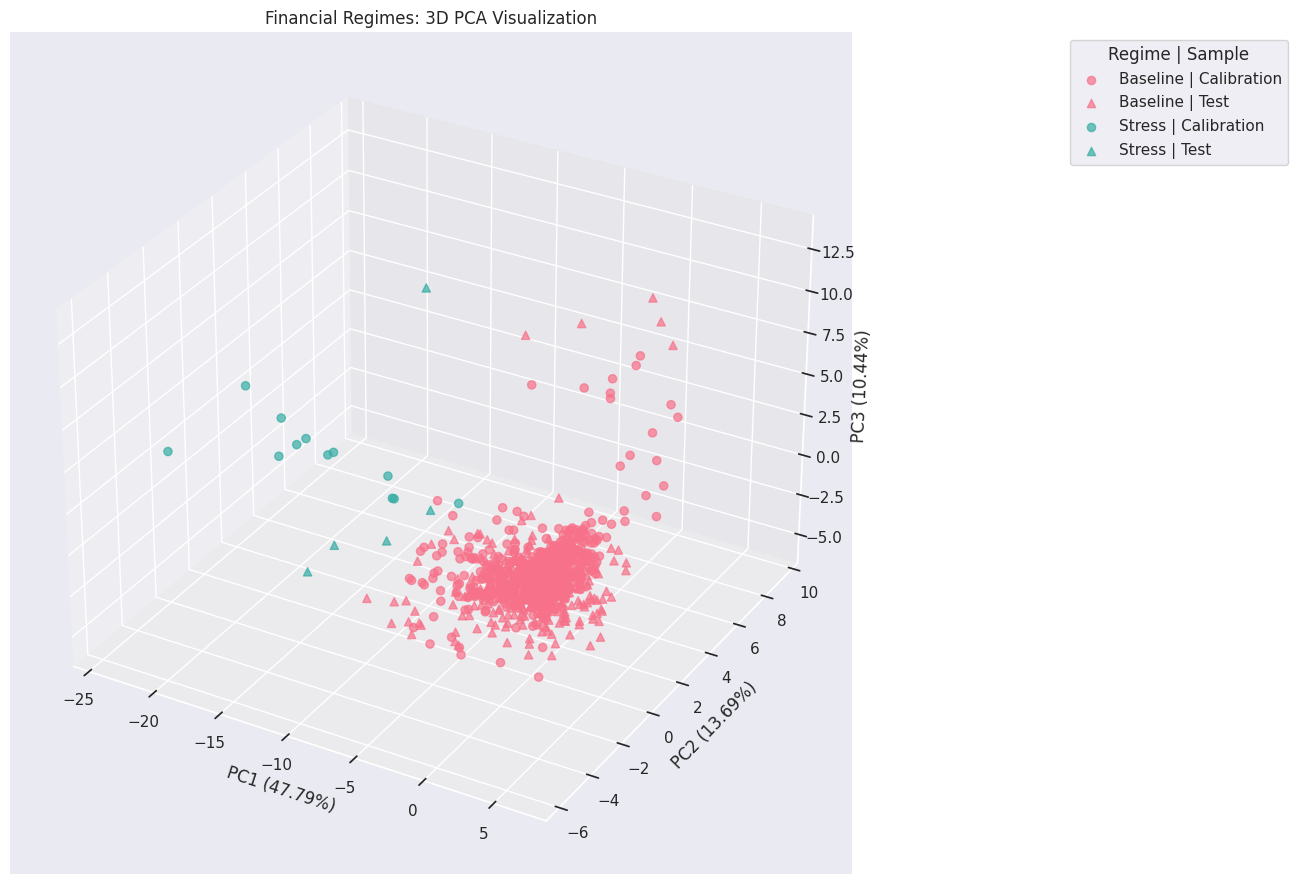

Financial 3D PCA total explained variance: 71.92%


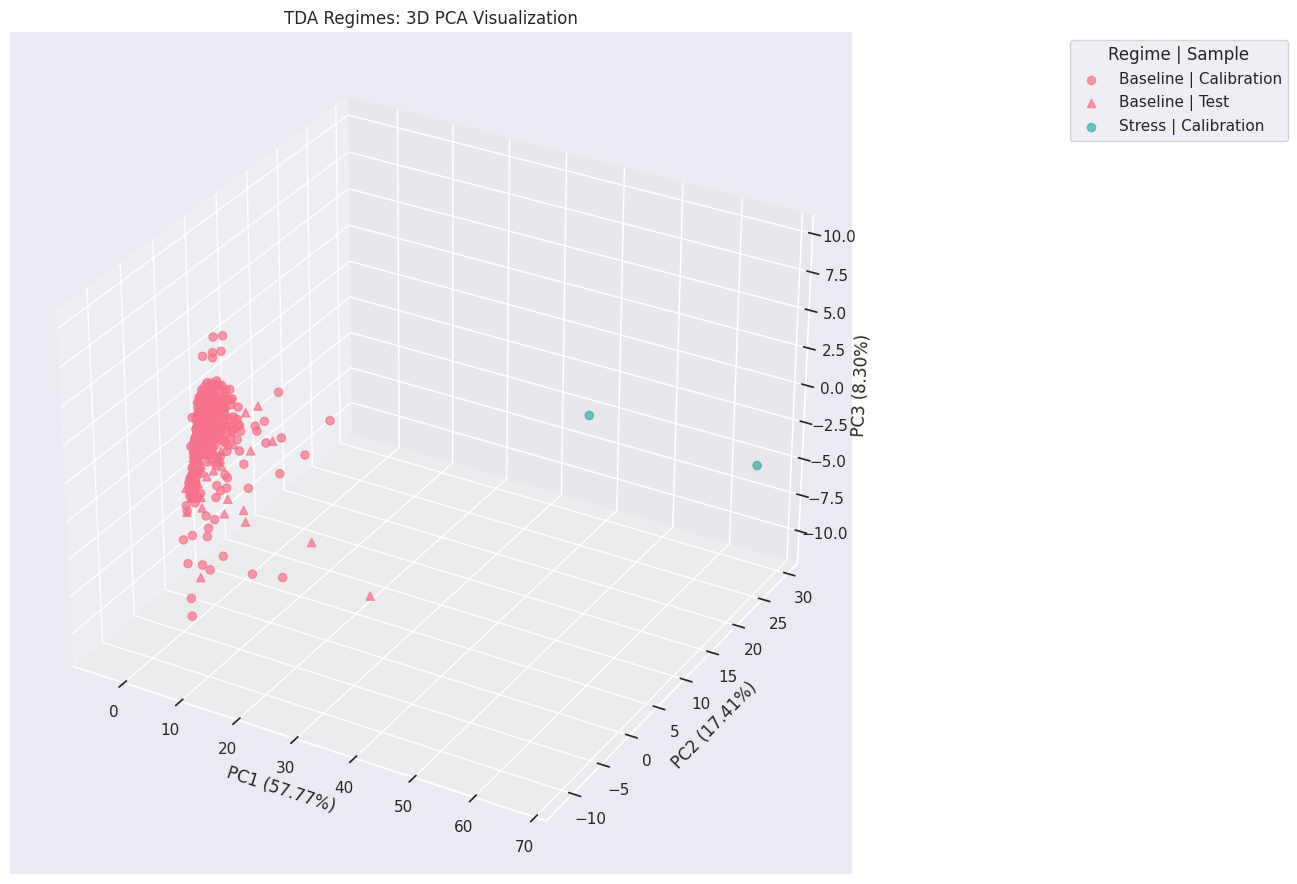

TDA 3D PCA total explained variance: 83.48%


In [47]:

pca_financial_3d, financial_pca_3d = plot_regime_pca_3d(
    "Financial", financial_regime_df, financial_cols
)

pca_tda_3d, tda_pca_3d = plot_regime_pca_3d(
    "TDA", tda_regime_df, tda_cols
)


## 14. Compare Financial and TDA regime sequences

Cluster agreement is evaluated separately for calibration and test observations. Adjusted Rand Index (ARI) compares cluster partitions without depending on cluster-number ordering. Semantic agreement and Cohen's kappa compare the regime labels assigned using the calibration-only financial-stress mapping.

In [40]:
def regime_agreement(financial_df, tda_df, sample_mask):
    financial_sample = financial_df.loc[sample_mask]
    tda_sample = tda_df.loc[sample_mask]
    if financial_sample.empty:
        return {"n": 0, "ari": np.nan, "semantic_agreement": np.nan, "cohen_kappa": np.nan}
    return {
        "n": len(financial_sample),
        "ari": adjusted_rand_score(financial_sample["cluster"], tda_sample["cluster"]),
        "semantic_agreement": float((
            financial_sample["regime_label"].to_numpy() == tda_sample["regime_label"].to_numpy()
        ).mean()),
        "cohen_kappa": cohen_kappa_score(
            financial_sample["regime_label"], tda_sample["regime_label"]
        ),
    }


calibration_mask = financial_regime_df["is_calibration"]
agreement_results = pd.DataFrame({
    "Calibration": regime_agreement(financial_regime_df, tda_regime_df, calibration_mask),
    "Test": regime_agreement(financial_regime_df, tda_regime_df, ~calibration_mask),
}).T

display(agreement_results.round(4))
regime_crosstab_test = pd.crosstab(
    financial_regime_df.loc[~calibration_mask, "regime_label"],
    tda_regime_df.loc[~calibration_mask, "regime_label"],
    normalize="all",
)
print("Test-period Financial versus TDA regime proportions")
display(regime_crosstab_test.round(4))

,n,ari,semantic_agreement,cohen_kappa
Calibration,524.0,0.2755,0.9809,0.281
Test,417.0,0.0000,0.9880,0.000


Test-period Financial versus TDA regime proportions


regime_label,Baseline
regime_label,
Baseline,0.988
Stress,0.012


Financial calibration transition probabilities


To,Baseline,Stress
From,,
Baseline,0.998,0.002
Stress,0.083,0.917


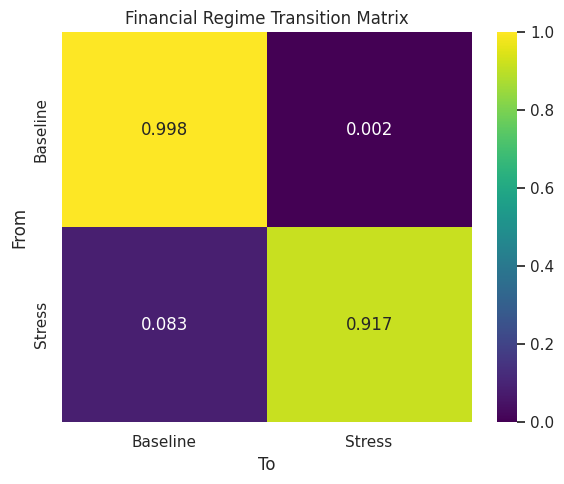

TDA calibration transition probabilities


To,Baseline,Stress
From,,
Baseline,0.998,0.002
Stress,0.500,0.500


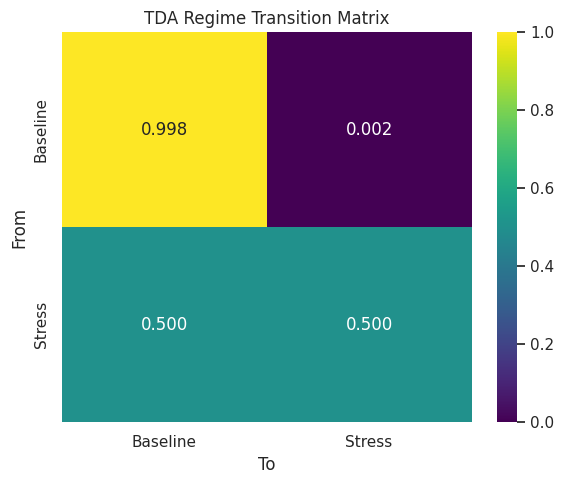

In [41]:
def transition_matrix(labels):
    labels = pd.Series(labels).reset_index(drop=True)
    current = labels.iloc[:-1].to_numpy()
    following = labels.iloc[1:].to_numpy()
    counts = pd.crosstab(current, following, rownames=["From"], colnames=["To"])
    probabilities = counts.div(counts.sum(axis=1), axis=0)
    return counts, probabilities


transition_results = {}
for feature_name, regime_df in {
    "Financial": financial_regime_df,
    "TDA": tda_regime_df,
}.items():
    calibration_regimes = regime_df.loc[regime_df["is_calibration"], "regime_label"]
    counts, probabilities = transition_matrix(calibration_regimes)
    transition_results[feature_name] = {"counts": counts, "probabilities": probabilities}
    print(f"{feature_name} calibration transition probabilities")
    display(probabilities.round(3))

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(probabilities, annot=True, fmt=".3f", cmap="viridis", vmin=0, vmax=1, ax=ax)
    ax.set_title(f"{feature_name} Regime Transition Matrix")
    plt.tight_layout()
    plt.show()

## 15. Pre-critical stress rates and regime-transition lead time

This section checks whether the `Stress` regime is more frequent in pre-critical calibration windows than across the full calibration period. It also measures the number of trading observations between the last observed `Baseline`-to-`Stress` transition and a test-period drawdown trigger. A missed transition is retained as a missing lead time, rather than being assigned an artificial value.

In [42]:
def precritical_stress_stats(regime_df):
    calibration = regime_df.loc[regime_df["is_calibration"]].copy()
    precritical = calibration.loc[calibration["is_precritical"]]
    overall_rate = float(calibration["regime_label"].eq("Stress").mean()) if len(calibration) else np.nan
    precritical_rate = float(precritical["regime_label"].eq("Stress").mean()) if len(precritical) else np.nan
    enrichment = precritical_rate / overall_rate if np.isfinite(overall_rate) and overall_rate > 0 else np.nan
    return {
        "n_calibration": len(calibration),
        "n_precritical": len(precritical),
        "overall_stress_rate": overall_rate,
        "precritical_stress_rate": precritical_rate,
        "stress_enrichment": enrichment,
    }


precritical_comparison = pd.DataFrame({
    "Financial": precritical_stress_stats(financial_regime_df),
    "TDA": precritical_stress_stats(tda_regime_df),
}).T
display(precritical_comparison.round(4))


def event_transition_timing(regime_df, events, trading_index, lookback=20):
    trading_index = pd.DatetimeIndex(trading_index)
    position = {pd.Timestamp(date): index for index, date in enumerate(trading_index)}
    evaluation_frame = regime_df.loc[~regime_df["is_calibration"]].sort_values("feature_end").copy()
    evaluation_frame["previous_regime"] = evaluation_frame["regime_label"].shift(1)
    transitions = evaluation_frame.loc[
        (evaluation_frame["previous_regime"] == "Baseline")
        & (evaluation_frame["regime_label"] == "Stress")
    ].copy()
    test_events = events.loc[events["sample"] == "Test"]

    rows = []
    for _, event in test_events.iterrows():
        trigger_date = pd.Timestamp(event["trigger_date"])
        if trigger_date not in position:
            continue
        trigger_position = position[trigger_date]
        candidates = transitions.loc[transitions["feature_end"] < trigger_date].copy()
        candidates["trading_position"] = pd.to_datetime(candidates["feature_end"]).map(position)
        candidates = candidates.loc[
            candidates["trading_position"].notna()
            & (candidates["trading_position"] >= trigger_position - lookback)
        ]

        if len(candidates):
            transition = candidates.sort_values("feature_end").iloc[-1]
            transition_date = pd.Timestamp(transition["feature_end"])
            lead_time = trigger_position - position[transition_date]
        else:
            transition_date = pd.NaT
            lead_time = np.nan

        rows.append({
            "trigger_date": trigger_date,
            "transition_date": transition_date,
            "lead_time_trading_days": lead_time,
            "transition_detected": pd.notna(transition_date),
        })

    result_columns = ["trigger_date", "transition_date", "lead_time_trading_days", "transition_detected"]
    return pd.DataFrame(rows, columns=result_columns)


leadtime_results = {}
for lookback in LEADTIME_LOOKBACKS:
    financial_timing = event_transition_timing(
        financial_regime_df, critical_events, ihsg_price.index, lookback=lookback
    ).rename(columns={
        "transition_date": "financial_transition_date",
        "lead_time_trading_days": "financial_lead_time",
        "transition_detected": "financial_detected",
    })
    tda_timing = event_transition_timing(
        tda_regime_df, critical_events, ihsg_price.index, lookback=lookback
    ).rename(columns={
        "transition_date": "tda_transition_date",
        "lead_time_trading_days": "tda_lead_time",
        "transition_detected": "tda_detected",
    })
    comparison = financial_timing.merge(tda_timing, on="trigger_date", how="outer")
    comparison["delta_lead_tda_minus_financial"] = (
        comparison["tda_lead_time"] - comparison["financial_lead_time"]
    )
    leadtime_results[lookback] = comparison

primary_leadtime = leadtime_results[PRIMARY_LEADTIME_LOOKBACK]
leadtime_summary = pd.DataFrame([
    {
        "lookback_trading_days": lookback,
        "n_test_events": len(table),
        "financial_detection_rate": table["financial_detected"].mean(),
        "tda_detection_rate": table["tda_detected"].mean(),
        "financial_median_lead_days": table["financial_lead_time"].median(),
        "tda_median_lead_days": table["tda_lead_time"].median(),
        "median_tda_minus_financial_lead_days": table["delta_lead_tda_minus_financial"].median(),
    }
    for lookback, table in leadtime_results.items()
])

print("Primary event-level lead-time comparison")
display(primary_leadtime)
print("Lead-time summary across evaluation windows")
display(leadtime_summary.round(4))

,n_calibration,n_precritical,overall_stress_rate,precritical_stress_rate,stress_enrichment
Financial,524.0,20.0,0.0229,0.0,0.0
TDA,524.0,20.0,0.0038,0.0,0.0


Primary event-level lead-time comparison


,trigger_date,financial_transition_date,financial_lead_time,financial_detected,tda_transition_date,tda_lead_time,tda_detected,delta_lead_tda_minus_financial
0,2018-04-26,NaT,NaN,False,NaT,NaN,False,NaN
1,2019-05-17,NaT,NaN,False,NaT,NaN,False,NaN
2,2020-02-24,NaT,NaN,False,NaT,NaN,False,NaN
3,2021-05-19,NaT,NaN,False,NaT,NaN,False,NaN
4,2023-01-11,NaT,NaN,False,NaT,NaN,False,NaN
5,2024-11-29,NaT,NaN,False,NaT,NaN,False,NaN
6,2026-03-04,NaT,NaN,False,NaT,NaN,False,NaN


Lead-time summary across evaluation windows


,lookback_trading_days,n_test_events,financial_detection_rate,tda_detection_rate,financial_median_lead_days,tda_median_lead_days,median_tda_minus_financial_lead_days
0,20,7,0.0,0.0,NaN,NaN,NaN
1,40,7,0.0,0.0,NaN,NaN,NaN
2,60,7,0.0,0.0,NaN,NaN,NaN


## 16. Plot Financial and TDA regimes on the IHSG series

The plot marks each sampled feature endpoint according to its assigned regime and overlays the reference drawdown triggers. The Financial and TDA plots are produced separately because their cluster assignments come from different feature spaces.

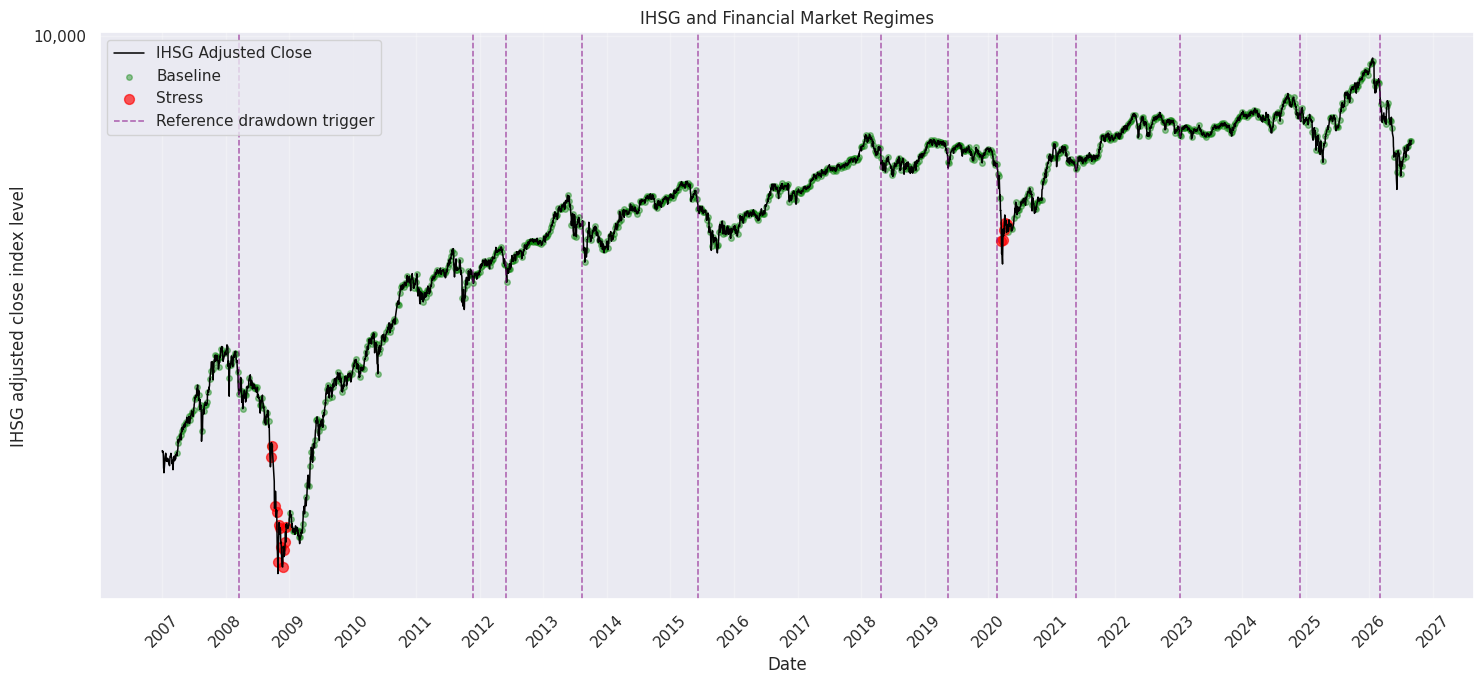

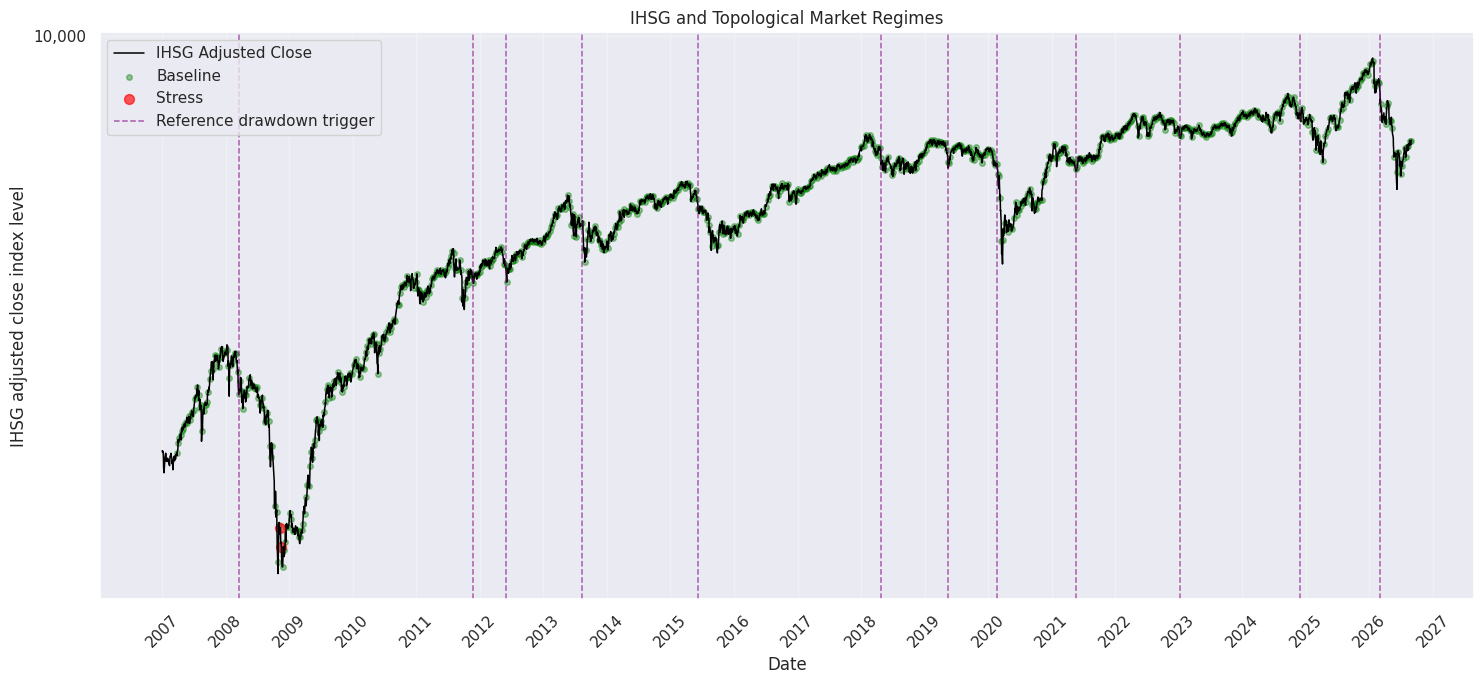

In [43]:
REGIME_COLORS = {
    "Baseline": "green",
    "Stress": "red",
    "Extreme Stress": "purple",
}


def plot_regimes_on_ihsg(regime_df, title):
    fig, ax = plt.subplots(figsize=(15, 7))
    ax.plot(
        ihsg_price.index, ihsg_price, linewidth=1.1, color="black",
        label="IHSG Adjusted Close",
    )

    for regime in regime_df["regime_label"].dropna().unique():
        subset = regime_df.loc[regime_df["regime_label"] == regime]
        point_prices = ihsg_price.reindex(pd.to_datetime(subset["feature_end"]))
        ax.scatter(
            subset["feature_end"], point_prices,
            s=50 if regime in ["Stress", "Extreme Stress"] else 16,
            alpha=0.65 if regime in ["Stress", "Extreme Stress"] else 0.4,
            color=REGIME_COLORS.get(regime, "gray"), label=regime,
        )

    for event_number, (_, event) in enumerate(critical_events.iterrows()):
        ax.axvline(
            event["trigger_date"], color="purple", linestyle="--", linewidth=1.1, alpha=0.6,
            label="Reference drawdown trigger" if event_number == 0 else None,
        )

    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel("IHSG adjusted close index level")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
    format_year_axis(ax)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_regimes_on_ihsg(financial_regime_df, "IHSG and Financial Market Regimes")
plot_regimes_on_ihsg(tda_regime_df, "IHSG and Topological Market Regimes")

## 17. Methodological notes and robustness checks

Interpret the results as a comparison between two representations of the same index, not as evidence that TDA must always outperform financial features.

Recommended robustness checks include:

1. Vary the rolling windows, for example `[20, 40, 60]` versus `[30, 60, 90]`.
2. Vary the embedding dimension and delay, such as $(m\in\{2,3,4\})$ and $(\tau\in\{1,2,3\})$.
3. Compare the chosen scaler with StandardScaler and MinMaxScaler.
4. Change the calibration cutoff and check whether the regime structure is stable.
5. Change the thresholds for reference drawdown events and compare event-level results.
6. Compare the primary two-cluster results against the exploratory Financial+TDA model, without treating the combined model as the main research result.

The embedding dimension, delay, feature windows, and critical-event thresholds are pre-specified configuration choices here. Their sensitivity should be reported before making strong claims about early-warning performance.

## 18. Save analysis outputs

All exports use IHSG-specific names. Tables are saved as CSV files to avoid requiring an optional Parquet engine. The main outputs include the cleaned IHSG OHLCV data, returns, regime features, reference drawdown events, clustering metrics, regime sequences, profiles, agreement statistics, transition matrices, and lead-time comparisons.

In [44]:
# Save the processed source series and engineered features.
ihsg_analysis.to_csv(OUTPUT_DIR / "ihsg_ohlcv_analysis_period.csv", index_label="Date")
log_returns.to_frame().to_csv(OUTPUT_DIR / "ihsg_daily_log_returns.csv", index_label="Date")
tda_returns.to_frame().to_csv(OUTPUT_DIR / "ihsg_standardized_log_returns_for_tda.csv", index_label="Date")
regime_features.to_csv(OUTPUT_DIR / "ihsg_multiscale_regime_features.csv", index=False)
critical_events.to_csv(OUTPUT_DIR / "ihsg_reference_drawdown_events.csv", index=False)
model_ranking.to_csv(OUTPUT_DIR / "clustering_model_ranking.csv", index=False)

financial_regime_df.to_csv(OUTPUT_DIR / "financial_regime_sequence_k2.csv", index=False)
tda_regime_df.to_csv(OUTPUT_DIR / "tda_regime_sequence_k2.csv", index=False)
combined_regime_df.to_csv(OUTPUT_DIR / "financial_tda_regime_sequence_k3_exploratory.csv", index=False)

financial_cluster_profile.to_csv(OUTPUT_DIR / "financial_cluster_profile.csv")
tda_cluster_profile.to_csv(OUTPUT_DIR / "tda_cluster_profile.csv")
combined_cluster_profile.to_csv(OUTPUT_DIR / "financial_tda_cluster_profile_exploratory.csv")
agreement_results.to_csv(OUTPUT_DIR / "financial_tda_regime_agreement.csv")
regime_crosstab_test.to_csv(OUTPUT_DIR / "financial_tda_test_regime_crosstab.csv")
precritical_comparison.to_csv(OUTPUT_DIR / "precritical_stress_comparison.csv")
transition_results["Financial"]["counts"].to_csv(OUTPUT_DIR / "financial_transition_counts_calibration.csv")
transition_results["Financial"]["probabilities"].to_csv(OUTPUT_DIR / "financial_transition_probabilities_calibration.csv")
transition_results["TDA"]["counts"].to_csv(OUTPUT_DIR / "tda_transition_counts_calibration.csv")
transition_results["TDA"]["probabilities"].to_csv(OUTPUT_DIR / "tda_transition_probabilities_calibration.csv")
primary_leadtime.to_csv(OUTPUT_DIR / "critical_event_leadtime_primary.csv", index=False)
leadtime_summary.to_csv(OUTPUT_DIR / "critical_event_leadtime_summary.csv", index=False)
for lookback, table in leadtime_results.items():
    table.to_csv(OUTPUT_DIR / f"critical_event_leadtime_{lookback}_trading_days.csv", index=False)

print("Analysis outputs saved to:", OUTPUT_DIR.resolve())

Analysis outputs saved to: /kaggle/working/data_ihsg_tda_kmeans


## 19. Pipeline summary

```text
Single IHSG OHLCV series
        ↓
Clean index-level data and calculate daily log returns
        ↓
Fit return standardization on the calibration period only
        ↓
 ┌───────────────────────────────┐
 │                               │
Financial features          Time-delay embedding
from IHSG OHLCV              of IHSG returns
 │                               ↓
 │                         Persistent homology H0/H1
 │                               ↓
 └──────────────┬────────────────┘
                ↓
       Separate K-Means models
    Financial k=2 versus TDA k=2
                ↓
 Calibration-only fit, fixed test assignment
                ↓
 Regime profiles, agreement, transitions,
 and drawdown-event timing evaluation
```

The main comparison uses only IHSG data. The exploratory Financial+TDA configuration is secondary. Any claim that TDA provides earlier warning should be based on test-period results and sensitivity analyses, not on cluster separation alone.